**Contributors: Anshuman · Inka · Juan Diego**

# Beacon Outfitters | Retail Replenishment Optimization

A reproducible decision-science workflow: validated retail data → constrained
optimization → benchmark evaluation → uncertainty analysis → shipment decisions.
Decide how many whole cases to ship and which stores receive trucks across
12 stores, 8 SKUs and 4 weeks. Results are modeled benchmark outcomes, not
realized company savings. The supplied demand forecast is an input, not a
prediction trained here.

**Run:** Runtime → Run all in a free Google Colab CPU runtime. Dependencies
install automatically; no checkout, file upload, private API key or paid runtime
is needed. The notebook includes all model source and verified CSV snapshots.
Inspect objective, bound and gap before calling a result optimal.


## 1. Automatic dependencies
Exact tested versions; Gurobi is optional. The bundled small-model license needs no private key; CP-SAT is the open-source fallback.

In [1]:
import sys, subprocess, os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/beacon-matplotlib')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
    'numpy==2.3.5', 'pandas==2.2.3', 'matplotlib==3.10.8', 'ortools==9.15.6755'])
optional = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', 'gurobipy==13.0.3'])
print('Gurobi package installed' if optional.returncode == 0 else 'Gurobi installation failed; CP-SAT remains available')
from IPython.display import display, Markdown



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Gurobi package installed



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 2. Data ingestion and validation
Fetch the pinned data revision with TLS verification and SHA-256 checks. If the network is unavailable, use identical embedded original CSV bytes. Unexpected online bytes fail validation rather than silently changing the experiment.

In [2]:
import pandas as pd
import hashlib, base64
from io import BytesIO
from urllib.request import urlopen
from urllib.error import URLError
DATA_REVISION = 'f8b2855f099bc4010c8b211fb083d1061292bf04'
RAW = f'https://raw.githubusercontent.com/agrawalanshuman/beacon-outfitters-replenishment/{DATA_REVISION}/data/raw/'
SNAPSHOTS = {'skus': 'c2t1LHNrdV9uYW1lLHVuaXRfY29zdCxyZXRhaWxfcHJpY2UsY2FzZV9wYWNrLGhvbGRpbmdfY29zdF9wZXJfdW5pdF93ZWVrDQpKMTAwLFNoZWxsIGphY2tldCw2MiwxMzksNiwwLjkNCkoyMDAsRG93biBwYXJrYSw5NSwyMjksNCwxLjQNCkYzMDAsRmxlZWNlIHB1bGxvdmVyLDI4LDY5LDgsMC40NQ0KQjQwMCxUcmFpbCBib290LDU0LDEyOSw2LDAuOA0KUDUwMCxIaWtpbmcgcGFudCwzMSw3OSw4LDAuNQ0KSDYwMCxXb29sIGJlYW5pZSw2LDI0LDEyLDAuMQ0KRzcwMCxJbnN1bGF0ZWQgZ2xvdmUsMTEsMzksMTIsMC4yDQpTODAwLE1lcmlubyBiYXNlIGxheWVyLDI0LDY0LDgsMC40DQo=', 'opening_inventory': 'c3RvcmVfaWQsc2t1LG9uX2hhbmRfdW5pdHMNClMwMSxKMTAwLDE2DQpTMDEsSjIwMCw0DQpTMDEsRjMwMCwxMw0KUzAxLEI0MDAsOQ0KUzAxLFA1MDAsMTUNClMwMSxINjAwLDIzDQpTMDEsRzcwMCwxOA0KUzAxLFM4MDAsMTMNClMwMixKMTAwLDEyDQpTMDIsSjIwMCw4DQpTMDIsRjMwMCwxMw0KUzAyLEI0MDAsNQ0KUzAyLFA1MDAsMTINClMwMixINjAwLDE3DQpTMDIsRzcwMCwxMQ0KUzAyLFM4MDAsMTENClMwMyxKMTAwLDcNClMwMyxKMjAwLDYNClMwMyxGMzAwLDE2DQpTMDMsQjQwMCw2DQpTMDMsUDUwMCw1DQpTMDMsSDYwMCwxNw0KUzAzLEc3MDAsMTANClMwMyxTODAwLDExDQpTMDQsSjEwMCw3DQpTMDQsSjIwMCw0DQpTMDQsRjMwMCw2DQpTMDQsQjQwMCw1DQpTMDQsUDUwMCw1DQpTMDQsSDYwMCwxNw0KUzA0LEc3MDAsMTMNClMwNCxTODAwLDMNClMwNSxKMTAwLDYNClMwNSxKMjAwLDINClMwNSxGMzAwLDE3DQpTMDUsQjQwMCw0DQpTMDUsUDUwMCw0DQpTMDUsSDYwMCwxNQ0KUzA1LEc3MDAsNg0KUzA1LFM4MDAsOA0KUzA2LEoxMDAsMw0KUzA2LEoyMDAsNQ0KUzA2LEYzMDAsNQ0KUzA2LEI0MDAsMw0KUzA2LFA1MDAsOA0KUzA2LEg2MDAsMTQNClMwNixHNzAwLDcNClMwNixTODAwLDMNClMwNyxKMTAwLDkNClMwNyxKMjAwLDINClMwNyxGMzAwLDcNClMwNyxCNDAwLDcNClMwNyxQNTAwLDkNClMwNyxINjAwLDExDQpTMDcsRzcwMCwzDQpTMDcsUzgwMCw2DQpTMDgsSjEwMCw0DQpTMDgsSjIwMCwyDQpTMDgsRjMwMCw0DQpTMDgsQjQwMCw1DQpTMDgsUDUwMCw1DQpTMDgsSDYwMCw3DQpTMDgsRzcwMCw4DQpTMDgsUzgwMCw0DQpTMDksSjEwMCwxMQ0KUzA5LEoyMDAsNA0KUzA5LEYzMDAsNg0KUzA5LEI0MDAsMw0KUzA5LFA1MDAsNw0KUzA5LEg2MDAsMTUNClMwOSxHNzAwLDkNClMwOSxTODAwLDExDQpTMTAsSjEwMCw0DQpTMTAsSjIwMCwyDQpTMTAsRjMwMCw2DQpTMTAsQjQwMCwyDQpTMTAsUDUwMCw3DQpTMTAsSDYwMCw4DQpTMTAsRzcwMCw1DQpTMTAsUzgwMCw0DQpTMTEsSjEwMCw2DQpTMTEsSjIwMCwzDQpTMTEsRjMwMCw3DQpTMTEsQjQwMCwyDQpTMTEsUDUwMCw1DQpTMTEsSDYwMCwxMw0KUzExLEc3MDAsNw0KUzExLFM4MDAsOA0KUzEyLEoxMDAsNQ0KUzEyLEoyMDAsMw0KUzEyLEYzMDAsMTENClMxMixCNDAwLDYNClMxMixQNTAwLDgNClMxMixINjAwLDEwDQpTMTIsRzcwMCw4DQpTMTIsUzgwMCw3DQo=', 'stores': 'c3RvcmVfaWQsc3RvcmVfbmFtZSxzaGVsZl9jYXBhY2l0eV91bml0cyxkZWxpdmVyeV9jb3N0X3Blcl92aXNpdCx0cnVja19jYXBhY2l0eV91bml0cw0KUzAxLEJvc3RvbiBCYWNrIEJheSw1MjAsMTgwLDQyMA0KUzAyLENhbWJyaWRnZSwzODAsMTUwLDQyMA0KUzAzLFByb3ZpZGVuY2UsMzYwLDIyMCw0MjANClMwNCxXb3JjZXN0ZXIsMzAwLDEyMCw0MjANClMwNSxIYXJ0Zm9yZCwzNDAsMjQwLDQyMA0KUzA2LFBvcnRsYW5kIE1FLDI4MCwzMjAsNDIwDQpTMDcsTWFuY2hlc3RlciBOSCwyNjAsMjYwLDQyMA0KUzA4LEJ1cmxpbmd0b24gVlQsMjIwLDM4MCw0MjANClMwOSxOZXcgSGF2ZW4sMzIwLDI2MCw0MjANClMxMCxTcHJpbmdmaWVsZCwyNjAsMjAwLDQyMA0KUzExLE5hc2h1YSwyNDAsMjQwLDQyMA0KUzEyLFBvcnRzbW91dGgsMjMwLDMwMCw0MjANCg==', 'dc_availability': 'c2t1LHdlZWssdW5pdHNfYXZhaWxhYmxlDQpKMTAwLDEsMTUwDQpKMTAwLDIsMTUwDQpKMTAwLDMsMTA4DQpKMTAwLDQsOTANCkoyMDAsMSw4OA0KSjIwMCwyLDg4DQpKMjAwLDMsNjQNCkoyMDAsNCw1Mg0KRjMwMCwxLDIyNA0KRjMwMCwyLDIyNA0KRjMwMCwzLDE2MA0KRjMwMCw0LDEzNg0KQjQwMCwxLDExNA0KQjQwMCwyLDExNA0KQjQwMCwzLDg0DQpCNDAwLDQsNjYNClA1MDAsMSwxNDQNClA1MDAsMiwxNDQNClA1MDAsMywxMDQNClA1MDAsNCw4OA0KSDYwMCwxLDI0MA0KSDYwMCwyLDI0MA0KSDYwMCwzLDE4MA0KSDYwMCw0LDE0NA0KRzcwMCwxLDE5Mg0KRzcwMCwyLDE5Mg0KRzcwMCwzLDE0NA0KRzcwMCw0LDEwOA0KUzgwMCwxLDE1Mg0KUzgwMCwyLDE1Mg0KUzgwMCwzLDExMg0KUzgwMCw0LDg4DQo=', 'demand_forecast': 'c3RvcmVfaWQsc2t1LHdlZWssZm9yZWNhc3RfdW5pdHMNClMwMSxKMTAwLDEsMTYNClMwMSxKMTAwLDIsMTMNClMwMSxKMTAwLDMsMTgNClMwMSxKMTAwLDQsMTcNClMwMSxKMjAwLDEsMTENClMwMSxKMjAwLDIsMTINClMwMSxKMjAwLDMsMTcNClMwMSxKMjAwLDQsMTkNClMwMSxGMzAwLDEsMjgNClMwMSxGMzAwLDIsMjcNClMwMSxGMzAwLDMsMjcNClMwMSxGMzAwLDQsMjINClMwMSxCNDAwLDEsMTQNClMwMSxCNDAwLDIsMTENClMwMSxCNDAwLDMsMTENClMwMSxCNDAwLDQsMTUNClMwMSxQNTAwLDEsMTgNClMwMSxQNTAwLDIsMTQNClMwMSxQNTAwLDMsMTkNClMwMSxQNTAwLDQsMTkNClMwMSxINjAwLDEsMjkNClMwMSxINjAwLDIsMjgNClMwMSxINjAwLDMsNDUNClMwMSxINjAwLDQsNDENClMwMSxHNzAwLDEsMjQNClMwMSxHNzAwLDIsMjMNClMwMSxHNzAwLDMsMjcNClMwMSxHNzAwLDQsMzYNClMwMSxTODAwLDEsMTgNClMwMSxTODAwLDIsMTgNClMwMSxTODAwLDMsMTcNClMwMSxTODAwLDQsMTgNClMwMixKMTAwLDEsMTINClMwMixKMTAwLDIsMTMNClMwMixKMTAwLDMsMTENClMwMixKMTAwLDQsMTMNClMwMixKMjAwLDEsNg0KUzAyLEoyMDAsMiw2DQpTMDIsSjIwMCwzLDE0DQpTMDIsSjIwMCw0LDExDQpTMDIsRjMwMCwxLDIxDQpTMDIsRjMwMCwyLDIxDQpTMDIsRjMwMCwzLDIwDQpTMDIsRjMwMCw0LDE3DQpTMDIsQjQwMCwxLDEwDQpTMDIsQjQwMCwyLDEwDQpTMDIsQjQwMCwzLDEwDQpTMDIsQjQwMCw0LDExDQpTMDIsUDUwMCwxLDE0DQpTMDIsUDUwMCwyLDEwDQpTMDIsUDUwMCwzLDExDQpTMDIsUDUwMCw0LDE0DQpTMDIsSDYwMCwxLDIwDQpTMDIsSDYwMCwyLDIwDQpTMDIsSDYwMCwzLDI2DQpTMDIsSDYwMCw0LDI4DQpTMDIsRzcwMCwxLDE4DQpTMDIsRzcwMCwyLDE1DQpTMDIsRzcwMCwzLDI1DQpTMDIsRzcwMCw0LDIxDQpTMDIsUzgwMCwxLDEyDQpTMDIsUzgwMCwyLDEzDQpTMDIsUzgwMCwzLDE2DQpTMDIsUzgwMCw0LDEyDQpTMDMsSjEwMCwxLDExDQpTMDMsSjEwMCwyLDEwDQpTMDMsSjEwMCwzLDE1DQpTMDMsSjEwMCw0LDEyDQpTMDMsSjIwMCwxLDkNClMwMyxKMjAwLDIsOA0KUzAzLEoyMDAsMywxMQ0KUzAzLEoyMDAsNCwxMQ0KUzAzLEYzMDAsMSwxNg0KUzAzLEYzMDAsMiwyMA0KUzAzLEYzMDAsMywyMA0KUzAzLEYzMDAsNCwyMA0KUzAzLEI0MDAsMSw4DQpTMDMsQjQwMCwyLDgNClMwMyxCNDAwLDMsMTANClMwMyxCNDAwLDQsMTENClMwMyxQNTAwLDEsMTENClMwMyxQNTAwLDIsMTENClMwMyxQNTAwLDMsMTENClMwMyxQNTAwLDQsMTENClMwMyxINjAwLDEsMjINClMwMyxINjAwLDIsMjENClMwMyxINjAwLDMsMjQNClMwMyxINjAwLDQsMzENClMwMyxHNzAwLDEsMTYNClMwMyxHNzAwLDIsMTMNClMwMyxHNzAwLDMsMjQNClMwMyxHNzAwLDQsMTgNClMwMyxTODAwLDEsMTINClMwMyxTODAwLDIsOQ0KUzAzLFM4MDAsMywxMQ0KUzAzLFM4MDAsNCwxMQ0KUzA0LEoxMDAsMSw5DQpTMDQsSjEwMCwyLDkNClMwNCxKMTAwLDMsMTENClMwNCxKMTAwLDQsMTANClMwNCxKMjAwLDEsNQ0KUzA0LEoyMDAsMiw1DQpTMDQsSjIwMCwzLDEwDQpTMDQsSjIwMCw0LDgNClMwNCxGMzAwLDEsMTENClMwNCxGMzAwLDIsMTUNClMwNCxGMzAwLDMsMTQNClMwNCxGMzAwLDQsMTUNClMwNCxCNDAwLDEsNg0KUzA0LEI0MDAsMiw3DQpTMDQsQjQwMCwzLDkNClMwNCxCNDAwLDQsOQ0KUzA0LFA1MDAsMSw4DQpTMDQsUDUwMCwyLDEyDQpTMDQsUDUwMCwzLDExDQpTMDQsUDUwMCw0LDkNClMwNCxINjAwLDEsMTcNClMwNCxINjAwLDIsMTgNClMwNCxINjAwLDMsMjQNClMwNCxINjAwLDQsMjQNClMwNCxHNzAwLDEsMTENClMwNCxHNzAwLDIsMTENClMwNCxHNzAwLDMsMTYNClMwNCxHNzAwLDQsMjANClMwNCxTODAwLDEsMTANClMwNCxTODAwLDIsOA0KUzA0LFM4MDAsMyw5DQpTMDQsUzgwMCw0LDEyDQpTMDUsSjEwMCwxLDExDQpTMDUsSjEwMCwyLDExDQpTMDUsSjEwMCwzLDEyDQpTMDUsSjEwMCw0LDEzDQpTMDUsSjIwMCwxLDgNClMwNSxKMjAwLDIsNg0KUzA1LEoyMDAsMyw5DQpTMDUsSjIwMCw0LDEwDQpTMDUsRjMwMCwxLDE0DQpTMDUsRjMwMCwyLDEzDQpTMDUsRjMwMCwzLDIwDQpTMDUsRjMwMCw0LDE2DQpTMDUsQjQwMCwxLDgNClMwNSxCNDAwLDIsNg0KUzA1LEI0MDAsMyw5DQpTMDUsQjQwMCw0LDExDQpTMDUsUDUwMCwxLDEyDQpTMDUsUDUwMCwyLDkNClMwNSxQNTAwLDMsMTMNClMwNSxQNTAwLDQsMTINClMwNSxINjAwLDEsMjENClMwNSxINjAwLDIsMTgNClMwNSxINjAwLDMsMjINClMwNSxINjAwLDQsMjYNClMwNSxHNzAwLDEsMTUNClMwNSxHNzAwLDIsMTUNClMwNSxHNzAwLDMsMTgNClMwNSxHNzAwLDQsMjMNClMwNSxTODAwLDEsMTENClMwNSxTODAwLDIsMTENClMwNSxTODAwLDMsMTMNClMwNSxTODAwLDQsMTQNClMwNixKMTAwLDEsOA0KUzA2LEoxMDAsMiw4DQpTMDYsSjEwMCwzLDkNClMwNixKMTAwLDQsMTINClMwNixKMjAwLDEsNg0KUzA2LEoyMDAsMiw3DQpTMDYsSjIwMCwzLDEwDQpTMDYsSjIwMCw0LDExDQpTMDYsRjMwMCwxLDEyDQpTMDYsRjMwMCwyLDE1DQpTMDYsRjMwMCwzLDEzDQpTMDYsRjMwMCw0LDEzDQpTMDYsQjQwMCwxLDcNClMwNixCNDAwLDIsNw0KUzA2LEI0MDAsMyw3DQpTMDYsQjQwMCw0LDcNClMwNixQNTAwLDEsOA0KUzA2LFA1MDAsMiw4DQpTMDYsUDUwMCwzLDEwDQpTMDYsUDUwMCw0LDkNClMwNixINjAwLDEsMTUNClMwNixINjAwLDIsMTkNClMwNixINjAwLDMsMjQNClMwNixINjAwLDQsMjcNClMwNixHNzAwLDEsMTQNClMwNixHNzAwLDIsMTUNClMwNixHNzAwLDMsMjMNClMwNixHNzAwLDQsMTcNClMwNixTODAwLDEsOA0KUzA2LFM4MDAsMiwxMA0KUzA2LFM4MDAsMywxMA0KUzA2LFM4MDAsNCwxMg0KUzA3LEoxMDAsMSw3DQpTMDcsSjEwMCwyLDgNClMwNyxKMTAwLDMsMTANClMwNyxKMTAwLDQsOA0KUzA3LEoyMDAsMSw3DQpTMDcsSjIwMCwyLDcNClMwNyxKMjAwLDMsOA0KUzA3LEoyMDAsNCwxMA0KUzA3LEYzMDAsMSwxMw0KUzA3LEYzMDAsMiwxMA0KUzA3LEYzMDAsMywxMw0KUzA3LEYzMDAsNCwxNA0KUzA3LEI0MDAsMSw2DQpTMDcsQjQwMCwyLDcNClMwNyxCNDAwLDMsNw0KUzA3LEI0MDAsNCw2DQpTMDcsUDUwMCwxLDkNClMwNyxQNTAwLDIsOQ0KUzA3LFA1MDAsMyw3DQpTMDcsUDUwMCw0LDcNClMwNyxINjAwLDEsMTMNClMwNyxINjAwLDIsMTUNClMwNyxINjAwLDMsMjUNClMwNyxINjAwLDQsMjQNClMwNyxHNzAwLDEsMTMNClMwNyxHNzAwLDIsMTINClMwNyxHNzAwLDMsMTUNClMwNyxHNzAwLDQsMTgNClMwNyxTODAwLDEsNw0KUzA3LFM4MDAsMiw4DQpTMDcsUzgwMCwzLDEwDQpTMDcsUzgwMCw0LDgNClMwOCxKMTAwLDEsNw0KUzA4LEoxMDAsMiw3DQpTMDgsSjEwMCwzLDkNClMwOCxKMTAwLDQsNw0KUzA4LEoyMDAsMSw0DQpTMDgsSjIwMCwyLDYNClMwOCxKMjAwLDMsOQ0KUzA4LEoyMDAsNCw5DQpTMDgsRjMwMCwxLDEwDQpTMDgsRjMwMCwyLDExDQpTMDgsRjMwMCwzLDEyDQpTMDgsRjMwMCw0LDkNClMwOCxCNDAwLDEsNA0KUzA4LEI0MDAsMiw1DQpTMDgsQjQwMCwzLDUNClMwOCxCNDAwLDQsNg0KUzA4LFA1MDAsMSw2DQpTMDgsUDUwMCwyLDgNClMwOCxQNTAwLDMsNw0KUzA4LFA1MDAsNCw4DQpTMDgsSDYwMCwxLDE0DQpTMDgsSDYwMCwyLDE1DQpTMDgsSDYwMCwzLDIzDQpTMDgsSDYwMCw0LDE5DQpTMDgsRzcwMCwxLDkNClMwOCxHNzAwLDIsMTANClMwOCxHNzAwLDMsMTINClMwOCxHNzAwLDQsMTQNClMwOCxTODAwLDEsNg0KUzA4LFM4MDAsMiw3DQpTMDgsUzgwMCwzLDgNClMwOCxTODAwLDQsOA0KUzA5LEoxMDAsMSw4DQpTMDksSjEwMCwyLDEwDQpTMDksSjEwMCwzLDE0DQpTMDksSjEwMCw0LDExDQpTMDksSjIwMCwxLDUNClMwOSxKMjAwLDIsNg0KUzA5LEoyMDAsMywxMQ0KUzA5LEoyMDAsNCwxMg0KUzA5LEYzMDAsMSwxNA0KUzA5LEYzMDAsMiwxNg0KUzA5LEYzMDAsMywxNQ0KUzA5LEYzMDAsNCwxNg0KUzA5LEI0MDAsMSw4DQpTMDksQjQwMCwyLDYNClMwOSxCNDAwLDMsOA0KUzA5LEI0MDAsNCw4DQpTMDksUDUwMCwxLDEwDQpTMDksUDUwMCwyLDEwDQpTMDksUDUwMCwzLDEyDQpTMDksUDUwMCw0LDkNClMwOSxINjAwLDEsMTgNClMwOSxINjAwLDIsMTQNClMwOSxINjAwLDMsMjUNClMwOSxINjAwLDQsMjQNClMwOSxHNzAwLDEsMTQNClMwOSxHNzAwLDIsMTANClMwOSxHNzAwLDMsMjANClMwOSxHNzAwLDQsMTcNClMwOSxTODAwLDEsOQ0KUzA5LFM4MDAsMiwxMQ0KUzA5LFM4MDAsMywxMg0KUzA5LFM4MDAsNCw5DQpTMTAsSjEwMCwxLDkNClMxMCxKMTAwLDIsOQ0KUzEwLEoxMDAsMyw5DQpTMTAsSjEwMCw0LDkNClMxMCxKMjAwLDEsNQ0KUzEwLEoyMDAsMiw2DQpTMTAsSjIwMCwzLDEwDQpTMTAsSjIwMCw0LDkNClMxMCxGMzAwLDEsMTANClMxMCxGMzAwLDIsMTINClMxMCxGMzAwLDMsMTQNClMxMCxGMzAwLDQsMTUNClMxMCxCNDAwLDEsNg0KUzEwLEI0MDAsMiw3DQpTMTAsQjQwMCwzLDcNClMxMCxCNDAwLDQsNg0KUzEwLFA1MDAsMSw5DQpTMTAsUDUwMCwyLDcNClMxMCxQNTAwLDMsMTANClMxMCxQNTAwLDQsOQ0KUzEwLEg2MDAsMSwxMg0KUzEwLEg2MDAsMiwxNg0KUzEwLEg2MDAsMywyMg0KUzEwLEg2MDAsNCwxOA0KUzEwLEc3MDAsMSwxMA0KUzEwLEc3MDAsMiw5DQpTMTAsRzcwMCwzLDE0DQpTMTAsRzcwMCw0LDEzDQpTMTAsUzgwMCwxLDcNClMxMCxTODAwLDIsOA0KUzEwLFM4MDAsMywxMA0KUzEwLFM4MDAsNCw4DQpTMTEsSjEwMCwxLDYNClMxMSxKMTAwLDIsOA0KUzExLEoxMDAsMywxMA0KUzExLEoxMDAsNCw5DQpTMTEsSjIwMCwxLDYNClMxMSxKMjAwLDIsNw0KUzExLEoyMDAsMyw5DQpTMTEsSjIwMCw0LDcNClMxMSxGMzAwLDEsMTANClMxMSxGMzAwLDIsMTANClMxMSxGMzAwLDMsMTQNClMxMSxGMzAwLDQsMTMNClMxMSxCNDAwLDEsNg0KUzExLEI0MDAsMiw1DQpTMTEsQjQwMCwzLDUNClMxMSxCNDAwLDQsNw0KUzExLFA1MDAsMSw4DQpTMTEsUDUwMCwyLDgNClMxMSxQNTAwLDMsNw0KUzExLFA1MDAsNCw5DQpTMTEsSDYwMCwxLDE2DQpTMTEsSDYwMCwyLDE1DQpTMTEsSDYwMCwzLDI0DQpTMTEsSDYwMCw0LDI1DQpTMTEsRzcwMCwxLDEwDQpTMTEsRzcwMCwyLDEzDQpTMTEsRzcwMCwzLDE0DQpTMTEsRzcwMCw0LDE5DQpTMTEsUzgwMCwxLDgNClMxMSxTODAwLDIsNg0KUzExLFM4MDAsMyw3DQpTMTEsUzgwMCw0LDEwDQpTMTIsSjEwMCwxLDgNClMxMixKMTAwLDIsNw0KUzEyLEoxMDAsMywxMA0KUzEyLEoxMDAsNCw3DQpTMTIsSjIwMCwxLDYNClMxMixKMjAwLDIsNg0KUzEyLEoyMDAsMywxMA0KUzEyLEoyMDAsNCwxMA0KUzEyLEYzMDAsMSwxMg0KUzEyLEYzMDAsMiw5DQpTMTIsRjMwMCwzLDExDQpTMTIsRjMwMCw0LDExDQpTMTIsQjQwMCwxLDUNClMxMixCNDAwLDIsNQ0KUzEyLEI0MDAsMyw3DQpTMTIsQjQwMCw0LDYNClMxMixQNTAwLDEsOA0KUzEyLFA1MDAsMiw3DQpTMTIsUDUwMCwzLDcNClMxMixQNTAwLDQsNw0KUzEyLEg2MDAsMSwxNQ0KUzEyLEg2MDAsMiwxMQ0KUzEyLEg2MDAsMywyMQ0KUzEyLEg2MDAsNCwyMQ0KUzEyLEc3MDAsMSwxMQ0KUzEyLEc3MDAsMiwxMA0KUzEyLEc3MDAsMywxNA0KUzEyLEc3MDAsNCwxNA0KUzEyLFM4MDAsMSw3DQpTMTIsUzgwMCwyLDcNClMxMixTODAwLDMsOQ0KUzEyLFM4MDAsNCw4DQo='}
SHA256 = {'skus': '8a5b203dda12926e79087ac44fcc49fd71743432144da48f328074d860d1eb76', 'opening_inventory': 'd1851a67e5ffe0c3033d4aaa1e382cf5274443de002bc3271c19b3d1c1b743c5', 'stores': 'c691079f918014bf1ce44c95861f600e1035291a4a54861ed3adfd79ede65672', 'dc_availability': '56904cdbc47ff0a61c20bc10b14672dfe3eb80110ef2166db7cf3b37112c33de', 'demand_forecast': 'dcaa5dd08f4de2decb6dc4d12eb7eac96d796c51ba45fa538d0782c1eed31278'}
data = {}
for name in ['stores','skus','demand_forecast','opening_inventory','dc_availability']:
    try:
        with urlopen(RAW + name + '.csv', timeout=20) as response:
            content = response.read()
        source = 'pinned data URL'
    except (URLError, TimeoutError, OSError) as exc:
        content = base64.b64decode(SNAPSHOTS[name])
        source = 'embedded original snapshot (' + type(exc).__name__ + ')'
    assert hashlib.sha256(content).hexdigest() == SHA256[name], 'Source checksum mismatch: ' + name
    data[name] = pd.read_csv(BytesIO(content))
    print(name, len(data[name]), source)


stores 12 pinned data URL
skus 8 pinned data URL
demand_forecast 384 pinned data URL


opening_inventory 96 pinned data URL
dc_availability 32 pinned data URL


In [3]:
"""Retail benchmark data, with checksum-verified offline snapshots."""
from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib
import pandas as pd

NAMES = ['stores', 'skus', 'demand_forecast', 'opening_inventory', 'dc_availability']

def load_data(root):
    return {n: pd.read_csv(Path(root) / f'{n}.csv') for n in NAMES}


def validate_data(d):
    import numpy as np
    expected = dict(zip(NAMES, [12, 8, 384, 96, 32]))
    keys = {'stores':['store_id'], 'skus':['sku'], 'demand_forecast':['store_id','sku','week'],
            'opening_inventory':['store_id','sku'], 'dc_availability':['sku','week']}
    numeric_columns = {
        'stores':['shelf_capacity_units','delivery_cost_per_visit','truck_capacity_units'],
        'skus':['unit_cost','retail_price','case_pack','holding_cost_per_unit_week'],
        'demand_forecast':['week','forecast_units'],
        'opening_inventory':['on_hand_units'], 'dc_availability':['week','units_available']}
    money = {'unit_cost','retail_price','holding_cost_per_unit_week','delivery_cost_per_visit'}
    assert set(d)==set(NAMES), 'Expected exactly five datasets'
    for name,t in d.items():
        required = set(keys[name]+numeric_columns[name])
        if name=='stores': required.add('store_name')
        if name=='skus': required.add('sku_name')
        assert set(t.columns)==required, f'{name}: unexpected schema'
        assert len(t)==expected[name], f'{name}: unexpected row count'
        assert not t.isna().any().any(), f'{name}: missing values'
        assert not t.duplicated(keys[name]).any(), f'{name}: duplicate keys'
        for col in numeric_columns[name]:
            assert pd.api.types.is_numeric_dtype(t[col]), f'{name}.{col}: numeric dtype required'
            assert np.isfinite(t[col]).all() and (t[col]>=0).all(), f'{name}.{col}: invalid range'
            scale=100 if col in money else 1
            assert np.allclose(t[col]*scale, np.round(t[col]*scale), atol=1e-8, rtol=0), f'{name}.{col}: invalid precision'
    S,K=set(d['stores'].store_id),set(d['skus'].sku)
    grids = {
        'demand_forecast':{(s,k,w) for s in S for k in K for w in [1,2,3,4]},
        'opening_inventory':{(s,k) for s in S for k in K},
        'dc_availability':{(k,w) for k in K for w in [1,2,3,4]}}
    for name,grid in grids.items():
        assert set(d[name][keys[name]].itertuples(index=False,name=None))==grid, f'{name}: incomplete/unknown identifiers'
    assert (d['skus'].case_pack>0).all(), 'Positive case packs required'
    assert (d['skus'].retail_price>d['skus'].unit_cost).all(), 'Positive margins required'
    assert (d['stores'][['shelf_capacity_units','truck_capacity_units','delivery_cost_per_visit']]>0).all().all()
    assert (d['skus'].holding_cost_per_unit_week>0).all()
    opening=d['opening_inventory'].groupby('store_id').on_hand_units.sum()
    assert (opening<=d['stores'].set_index('store_id').shelf_capacity_units).all(), 'Opening inventory exceeds shared shelf'
    return True


def parameters(d):
    st, sk = d['stores'].set_index('store_id'), d['skus'].set_index('sku')
    return dict(S=list(st.index), K=list(sk.index), W=[1,2,3,4],
        shelf=st.shelf_capacity_units.to_dict(), truck=st.truck_capacity_units.to_dict(),
        vcost=st.delivery_cost_per_visit.to_dict(), pack=sk.case_pack.to_dict(),
        margin=(sk.retail_price-sk.unit_cost).to_dict(), hold=sk.holding_cost_per_unit_week.to_dict(),
        fc=d['demand_forecast'].set_index(['store_id','sku','week']).forecast_units.to_dict(),
        opening=d['opening_inventory'].set_index(['store_id','sku']).on_hand_units.to_dict(),
        avail=d['dc_availability'].set_index(['sku','week']).units_available.to_dict())

assert validate_data(data)
p = parameters(data)
for name, table in data.items():
    print(name, table.dtypes.to_dict()); display(table.describe(include='all'))

stores {'store_id': dtype('O'), 'store_name': dtype('O'), 'shelf_capacity_units': dtype('int64'), 'delivery_cost_per_visit': dtype('int64'), 'truck_capacity_units': dtype('int64')}


,store_id,store_name,shelf_capacity_units,delivery_cost_per_visit,truck_capacity_units
count,12,12,12.000000,12.000000,12.0
unique,12,12,NaN,NaN,NaN
top,S01,Boston Back Bay,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN
mean,NaN,NaN,309.166667,239.166667,420.0
std,NaN,NaN,84.149038,72.920671,0.0
min,NaN,NaN,220.000000,120.000000,420.0
25%,NaN,NaN,255.000000,195.000000,420.0
50%,NaN,NaN,290.000000,240.000000,420.0
75%,NaN,NaN,345.000000,270.000000,420.0


skus {'sku': dtype('O'), 'sku_name': dtype('O'), 'unit_cost': dtype('int64'), 'retail_price': dtype('int64'), 'case_pack': dtype('int64'), 'holding_cost_per_unit_week': dtype('float64')}


,sku,sku_name,unit_cost,retail_price,case_pack,holding_cost_per_unit_week
count,8,8,8.000000,8.000000,8.000000,8.000000
unique,8,8,NaN,NaN,NaN,NaN
top,J100,Shell jacket,NaN,NaN,NaN,NaN
freq,1,1,NaN,NaN,NaN,NaN
mean,NaN,NaN,38.875000,96.500000,8.000000,0.593750
std,NaN,NaN,29.695779,66.654761,2.828427,0.422947
min,NaN,NaN,6.000000,24.000000,4.000000,0.100000
25%,NaN,NaN,20.750000,57.750000,6.000000,0.350000
50%,NaN,NaN,29.500000,74.000000,8.000000,0.475000
75%,NaN,NaN,56.000000,131.500000,9.000000,0.825000


demand_forecast {'store_id': dtype('O'), 'sku': dtype('O'), 'week': dtype('int64'), 'forecast_units': dtype('int64')}


,store_id,sku,week,forecast_units
count,384,384,384.000000,384.000000
unique,12,8,NaN,NaN
top,S01,J100,NaN,NaN
freq,32,48,NaN,NaN
mean,NaN,NaN,2.500000,12.455729
std,NaN,NaN,1.119493,6.034117
min,NaN,NaN,1.000000,4.000000
25%,NaN,NaN,1.750000,8.000000
50%,NaN,NaN,2.500000,11.000000
75%,NaN,NaN,3.250000,15.000000


opening_inventory {'store_id': dtype('O'), 'sku': dtype('O'), 'on_hand_units': dtype('int64')}


,store_id,sku,on_hand_units
count,96,96,96.000000
unique,12,8,NaN
top,S01,J100,NaN
freq,8,12,NaN
mean,NaN,NaN,7.854167
std,NaN,NaN,4.490878
min,NaN,NaN,2.000000
25%,NaN,NaN,4.750000
50%,NaN,NaN,7.000000
75%,NaN,NaN,11.000000


dc_availability {'sku': dtype('O'), 'week': dtype('int64'), 'units_available': dtype('int64')}


,sku,week,units_available
count,32,32.000000,32.000000
unique,8,NaN,NaN
top,J100,NaN,NaN
freq,4,NaN,NaN
mean,NaN,2.500000,135.500000
std,NaN,1.135924,51.546409
min,NaN,1.000000,52.000000
25%,NaN,1.750000,89.500000
50%,NaN,2.500000,140.000000
75%,NaN,3.250000,154.000000


## 3. Demand, supply and store economics
Shelf capacity is shared by all SKUs and is checked before sales. Unit margin is retail price less unit cost. A small store can have the same truck capacity as a large one, but less volume to spread its visit cost across.

,store_id,store_name,shelf_capacity_units,delivery_cost_per_visit,truck_capacity_units
0,S01,Boston Back Bay,520,180,420
1,S02,Cambridge,380,150,420
2,S03,Providence,360,220,420
3,S04,Worcester,300,120,420
4,S05,Hartford,340,240,420
5,S06,Portland ME,280,320,420
6,S07,Manchester NH,260,260,420
7,S08,Burlington VT,220,380,420
8,S09,New Haven,320,260,420
9,S10,Springfield,260,200,420


,sku,sku_name,unit_cost,retail_price,case_pack,holding_cost_per_unit_week,margin
0,J100,Shell jacket,62,139,6,0.90,77
1,J200,Down parka,95,229,4,1.40,134
2,F300,Fleece pullover,28,69,8,0.45,41
3,B400,Trail boot,54,129,6,0.80,75
4,P500,Hiking pant,31,79,8,0.50,48
5,H600,Wool beanie,6,24,12,0.10,18
6,G700,Insulated glove,11,39,12,0.20,28
7,S800,Merino base layer,24,64,8,0.40,40


,demand
week,
1,1062
2,1053
3,1338
4,1330


,demand,DC_supply,opening,shortage
sku,,,,
B400,370,378,57,-65
F300,724,744,111,-131
G700,773,636,105,32
H600,1035,804,167,64
J100,491,498,90,-97
J200,415,292,45,78
P500,482,480,90,-88
S800,493,504,89,-100


,store_name,shelf_capacity_units,delivery_cost_per_visit,truck_capacity_units,four_week_demand,shelf_to_demand,visit_cost_per_forecast_week_unit
store_id,,,,,,,
S11,Nashua,240,240,420,331,0.725076,2.900302
S06,Portland ME,280,320,420,381,0.734908,3.359580
S08,Burlington VT,220,380,420,294,0.748299,5.170068
S12,Portsmouth,230,300,420,307,0.749186,3.908795
S07,Manchester NH,260,260,420,341,0.762463,3.049853
S01,Boston Back Bay,520,180,420,672,0.773810,1.071429
S03,Providence,360,220,420,456,0.789474,1.929825
S02,Cambridge,380,150,420,481,0.790021,1.247401
S05,Hartford,340,240,420,430,0.790698,2.232558


Total shelf capacity: 3710 Opening stock: 754


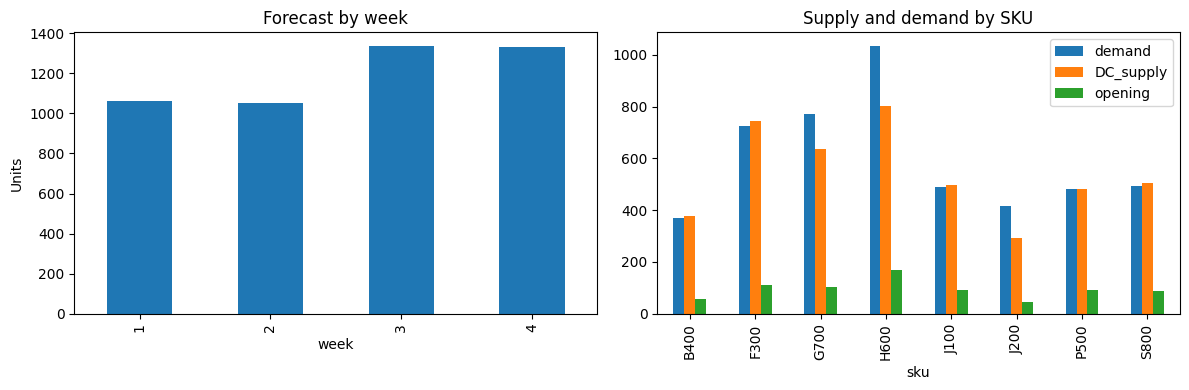

In [4]:
display(data['stores']); display(data['skus'].assign(margin=lambda x: x.retail_price-x.unit_cost))
by_week=data['demand_forecast'].groupby('week').forecast_units.sum()
display(by_week.to_frame('demand'))
supply_demand=pd.concat([
    data['demand_forecast'].groupby('sku').forecast_units.sum().rename('demand'),
    data['dc_availability'].groupby('sku').units_available.sum().rename('DC_supply'),
    data['opening_inventory'].groupby('sku').on_hand_units.sum().rename('opening')],axis=1)
supply_demand['shortage']=supply_demand.demand-supply_demand.DC_supply-supply_demand.opening
display(supply_demand)
store_stats=data['stores'].set_index('store_id').join(data['demand_forecast'].groupby('store_id').forecast_units.sum().rename('four_week_demand'))
store_stats['shelf_to_demand']=store_stats.shelf_capacity_units/store_stats.four_week_demand
store_stats['visit_cost_per_forecast_week_unit']=store_stats.delivery_cost_per_visit/(store_stats.four_week_demand/4)
display(store_stats.sort_values('shelf_to_demand'))
print('Total shelf capacity:',data['stores'].shelf_capacity_units.sum(),'Opening stock:',data['opening_inventory'].on_hand_units.sum())
import matplotlib.pyplot as plt
fig, axes=plt.subplots(1,2,figsize=(12,4))
by_week.plot.bar(ax=axes[0],title='Forecast by week',ylabel='Units')
supply_demand[['demand','DC_supply','opening']].plot.bar(ax=axes[1],title='Supply and demand by SKU')
plt.tight_layout(); plt.show()


## 4. Mathematical formulation
# Four-week replenishment formulation

For stores s, SKUs k and weeks w, choose integer cases c, binary visits y,
and nonnegative continuous sales a, lost demand l, and ending inventory i.
Let p be case-pack units, m retail minus unit cost, h holding cost per unit/week,
f forecast, I opening inventory, A weekly DC release, C shelf units, T truck units,
and v cost per visit.

Maximize sum(m[k] a[s,k,w] - h[k] i[s,k,w]) - sum(v[s] y[s,w]).

- Flow: i_previous + p[k] c[s,k,w] = a[s,k,w] + i[s,k,w], using I in week 1.
- Demand: a[s,k,w] + l[s,k,w] = f[s,k,w].
- Shelf: sum_k(i_previous + p[k] c[s,k,w]) <= C[s]. This is the shared shelf after arrival BEFORE sales.
- Truck: sum_k p[k] c[s,k,w] <= T[s] y[s,w]. Actual capacity is the linking bound.
- DC: sum_{s,t<=w} p[k] c[s,k,t] <= sum_{t<=w} A[k,t].

Unit costs occur once, inside margin. Opening stock uses the benchmark margin
convention; this is not a cash-flow or sunk-cost valuation of opening stock.
No end-of-horizon salvage, backorders, routing, or service floor is invented.

## Why integer sales are comparable

With cases and visits fixed, margins are positive and constant across weeks,
and holding costs are positive. Selling an available unit now rather than
withholding it for later cannot reduce total sales revenue, saves holding cost,
and frees shelf space. Therefore an optimal recourse policy sells
`min(available units, forecast)` in each week for each SKU. This exchange
argument guarantees an integral optimum for integer data, and an exact
fifth-unit optimum for the scaled ±20% scenarios. No general multicommodity
network integrality assumption is needed. Gurobi keeps sales/lost/inventory
continuous in the MILP formulation; CP-SAT represents them in fifths,
with currency in cents. We compare objectives and independently check numerical
integrality in the base data. This argument relies on the benchmark's positive,
time-invariant margins and holding costs, not arbitrary future variants.

The base model has 1,584 variables: 384 each for cases, sales, lost, inventory,
and 48 visits. Gurobi's bundled restricted license can solve this small benchmark
model without an API key. If unavailable, CP-SAT solves the same scaled model.
A time-limited incumbent is reported as feasible with its bound and gap.


## 5. Tested model, baselines, scenarios and independent verification
# Assumptions and scenario design

The model is a deterministic retail benchmark. Demand forecasts are supplied
inputs, not predictions trained by this project. Four-week contribution is a
modeled accounting outcome, not realized revenue, cash flow or audited savings.

- Store shelf capacity is shared across SKUs and enforced immediately after
  delivery, before that week's sales. Trucks have actual unit capacities.
- Unused DC release carries forward; future releases cannot be borrowed.
- Shipments are whole case packs. Sales and remaining stock are continuous in
  the MILP. The CP-SAT model uses exact fifth-unit quantities and integer cents.
- Margin is retail price minus unit cost, including sales from opening stock.
  Unit costs are counted once. No terminal salvage value, backorders, routing,
  warehouse storage limit, service floor or supplier lead time is invented.
- Demand stress: multiply every SKU's week 3–4 forecast by 0.8 or 1.2. Weeks 1–2
  are unchanged. Fractional demand is retained exactly, not rounded. These are
  direct ±20% tests, not a probabilistic forecast interval.
- Perfect-foresight scenarios reoptimize independently. Fixed-policy scenarios
  hold base shipments and visits constant, adjusting sales and remaining stock.
  These evaluate different questions and are reported separately.
- Extra-supply experiments add 100 units of one SKU at the start of week 1,
  identically across SKUs. Reported gains are finite reoptimization values, not
  LP shadow prices, purchase prices or returns net of a new supplier premium.
- Alternating-week policy: each store chooses either weeks 1/3 or weeks 2/4,
  and can skip a visit. It is a constrained comparison, not a routing solution.
- No-delivery baseline optimizes sales from opening stock with zero truck costs.
- Feasible heuristic: each week add DC releases, process stores in ascending ID,
  prioritize descending unit margin (SKU-ID ties), request cases for current
  demand net of stock, round up requests, and cap by remaining DC, shelf and
  truck capacity. Fixed-shipment sales recourse is then optimized consistently.
  This is a specified benchmark, not an observed company policy.

All scenarios use the same accounting and constraints. Summary differences
versus baselines refer to the *base-demand* benchmark, even for stress scenarios;
use fixed-policy comparisons to assess forecast adaptation. Equivalent optimum
allocations may differ across runs; their fixed-policy stress performance can
also differ. Solver runtime depends on hardware, versions and time limits.

See [data provenance](data_provenance.md) for original source credit and hashes.


In [5]:
"""Same replenishment model through Gurobi and exact-scaled CP-SAT."""
import time
import math
import pandas as pd


def solve(p, backend='cp-sat', fixed=None, no_ship=False, alternate=False, limit=120):
    if backend not in {'gurobi', 'cp-sat'}:
        raise ValueError(f'Unsupported backend: {backend}')
    S,K,W = (p[x] for x in ['S','K','W'])
    keys=[(s,k,w) for s in S for k in K for w in W]
    sw=[(s,w) for s in S for w in W]
    cp = backend == 'cp-sat'
    scale=5 if cp else 1  # 0.8 / 1.2 demand is exact in fifths; no rounding.
    if cp:
        import ortools
        from ortools.sat.python import cp_model
        model=cp_model.CpModel()
        version=ortools.__version__
        def var(lo,hi,name,integer=True): return model.new_int_var(int(lo),int(hi),name)
        add=model.add
    else:
        import gurobipy as gp
        model=gp.Model('beacon');model.Params.OutputFlag=0
        model.Params.TimeLimit=limit; model.Params.Seed=839; model.Params.Threads=2
        model.Params.MIPGap=0;model.Params.MIPGapAbs=0.001
        version='.'.join(map(str,gp.gurobi.version()))
        def var(lo,hi,name,integer=True):
            return model.addVar(lb=lo,ub=hi,vtype=gp.GRB.INTEGER if integer else gp.GRB.CONTINUOUS,name=name)
        add=model.addConstr
    def q(x):
        v=x*scale
        if cp and abs(v-round(v))>1e-6: raise ValueError('Quantity not exact in fifths')
        return int(round(v)) if cp else v
    cases={t:var(0, int(min(p['truck'][t[0]],p['shelf'][t[0]])//p['pack'][t[1]]),f'cases_{t}') for t in keys}
    sales={t:var(0,q(p['fc'][t]),f'sales_{t}',False) for t in keys}
    lost={t:var(0,q(p['fc'][t]),f'lost_{t}',False) for t in keys}
    inv={t:var(0,q(p['shelf'][t[0]]),f'inv_{t}',False) for t in keys}
    visit={t:var(0,1,f'visit_{t}') for t in sw}
    for s,k,w in keys:
        t=(s,k,w); prev=q(p['opening'][s,k]) if w==1 else inv[s,k,w-1]
        add(prev+q(p['pack'][k])*cases[t]==sales[t]+inv[t])
        add(sales[t]+lost[t]==q(p['fc'][t]))
        if no_ship: add(cases[t]==0)
        if fixed is not None: add(cases[t]==int(fixed['cases'][t]))
    for s,w in sw:
        units=sum(q(p['pack'][k])*cases[s,k,w] for k in K)
        prev=sum(q(p['opening'][s,k]) if w==1 else inv[s,k,w-1] for k in K)
        add(prev+units<=q(p['shelf'][s]))
        add(units<=q(p['truck'][s])*visit[s,w])
        if fixed is not None: add(visit[s,w]==int(fixed['visit'][s,w]))
    if alternate:
        # Each store chooses either weeks 1&3 or weeks 2&4, and may skip a visit.
        phase={s:var(0,1,f'phase_{s}') for s in S}
        for s,w in sw: add(visit[s,w] <= (phase[s] if w%2 else 1-phase[s]))
    for k in K:
        for w in W:
            add(sum(q(p['pack'][k])*cases[s,k,t] for s in S for t in W if t<=w)
                <=q(sum(p['avail'][k,t] for t in W if t<=w)))
    def cents(x):
        assert abs(100*x-round(100*x))<1e-6
        return int(round(100*x))
    objective=sum(cents(p['margin'][k])*sales[s,k,w]-cents(p['hold'][k])*inv[s,k,w] for s,k,w in keys)-sum(cents(p['vcost'][s])*scale*visit[s,w] for s,w in sw)
    start=time.perf_counter()
    if cp:
        model.maximize(objective); solver=cp_model.CpSolver()
        solver.parameters.max_time_in_seconds=limit;solver.parameters.num_search_workers=2;solver.parameters.random_seed=839
        status=solver.solve(model);status_name=solver.status_name(status)
        if status not in [cp_model.OPTIMAL,cp_model.FEASIBLE]: raise RuntimeError(status_name)
        value=solver.value; obj=solver.objective_value/(100*scale);bound=solver.best_objective_bound/(100*scale)
    else:
        model.setObjective(objective, gp.GRB.MAXIMIZE);model.optimize()
        if not model.SolCount: raise RuntimeError(f'Gurobi status {model.Status}: no incumbent')
        status_name='OPTIMAL' if model.Status==gp.GRB.OPTIMAL else f'FEASIBLE_STATUS_{model.Status}'
        value=lambda v:v.X; obj=model.ObjVal/100;bound=model.ObjBound/100
    rows=[]
    for s,k,w in keys:
        t=s,k,w
        rows.append(dict(store_id=s,sku=k,week=w,cases=int(round(value(cases[t]))),
                         units_shipped=int(round(value(cases[t])))*p['pack'][k],
                         sales=value(sales[t])/scale,lost=value(lost[t])/scale,inventory=value(inv[t])/scale))
    trucks=pd.DataFrame([dict(store_id=s,week=w,visit=int(round(value(visit[s,w])))) for s,w in sw])
    return dict(plan=pd.DataFrame(rows), trucks=trucks, objective=obj, status=status_name, bound=bound,
                gap=abs(bound-obj)/max(1,abs(obj)), runtime=time.perf_counter()-start,solver=backend,version=version)

In [6]:
"""Constraint and accounting checks independent of model expressions."""
import numpy as np
import pandas as pd

def verify(p,r):
    t=r['plan'].set_index(['store_id','sku','week']);v=r['trucks'].set_index(['store_id','week']).visit
    checks=[]
    def check(family,error): checks.append((family,float(error),float(error)<=1e-5))
    check('finite',0 if np.isfinite(t.to_numpy()).all() else float('inf'))
    check('nonnegative',max(0,-t.to_numpy().min()))
    check('whole_cases',abs(t.cases-t.cases.round()).max())
    for s in p['S']:
        for w in p['W']:
            row=t.loc[(s,slice(None),w),:]
            prev={k:p['opening'][s,k] if w==1 else t.loc[(s,k,w-1),'inventory'] for k in p['K']}
            check('shelf',max(0,sum(prev.values())+row.units_shipped.sum()-p['shelf'][s]))
            check('truck',max(0,row.units_shipped.sum()-p['truck'][s]*v[s,w]))
            check('binary_visit',min(abs(v[s,w]),abs(v[s,w]-1)))
            check('zero_delivery_visit',int(v[s,w]==1 and row.units_shipped.sum()<1e-6))
            for k in p['K']:
                a=t.loc[s,k,w]
                check('flow',abs(prev[k]+a.units_shipped-a.sales-a.inventory))
                check('demand',abs(a.sales+a.lost-p['fc'][s,k,w]))
                check('case_units',abs(a.units_shipped-a.cases*p['pack'][k]))
    for k in p['K']:
        for w in p['W']:
            check('cumulative_dc',max(0,t.reset_index().query('sku==@k and week<=@w').units_shipped.sum()-sum(p['avail'][k,j] for j in p['W'] if j<=w)))
    a=r['plan']; margin=sum(p['margin'][z.sku]*z.sales for z in a.itertuples())
    holding=sum(p['hold'][z.sku]*z.inventory for z in a.itertuples())
    delivery=sum(p['vcost'][z.store_id]*z.visit for z in r['trucks'].itertuples())
    check('objective',abs(margin-holding-delivery-r['objective']))
    result=pd.DataFrame(checks,columns=['family','violation','passed']).groupby('family',as_index=False).agg(violation=('violation','max'),passed=('passed','all'))
    assert result.passed.all(), result.to_string()
    return result,dict(profit=margin-holding-delivery,sales_margin=margin,holding_cost=holding,delivery_cost=delivery,
        units_sold=a.sales.sum(),units_lost=a.lost.sum(),fill_rate=a.sales.sum()/sum(p['fc'].values()),
        cases=a.cases.sum(),units_shipped=a.units_shipped.sum(),visits=r['trucks'].visit.sum())

In [7]:
"""Deterministic feasible weekly-forecast heuristic, never a relaxed plan."""
import math
from copy import deepcopy

def naive_policy(p):
    stock=dict(p['opening']); dc={k:0 for k in p['K']}; cases={};visit={}
    # Stable IDs are tie-breaks; high margin per unit SKUs first.
    order=sorted(p['K'],key=lambda k:(-p['margin'][k],k))
    for w in p['W']:
        for k in p['K']: dc[k]+=p['avail'][k,w]
        for s in sorted(p['S']):
            room=p['shelf'][s]-sum(stock[s,k] for k in p['K']); truck=p['truck'][s]
            for k in order:
                pack=p['pack'][k];wanted=max(0,math.ceil((p['fc'][s,k,w]-stock[s,k])/pack))
                c=min(wanted,int(dc[k]//pack),int(room//pack),int(truck//pack))
                cases[s,k,w]=c;units=c*pack;stock[s,k]+=units;dc[k]-=units;room-=units;truck-=units
            visit[s,w]=int(truck<p['truck'][s])
            for k in p['K']: stock[s,k]-=min(stock[s,k],p['fc'][s,k,w])
    return dict(cases=cases,visit=visit)

In [8]:
from copy import deepcopy

def cold_snap(p,factor):
    # Stress-test all SKUs in weeks 3–4; preserve the first two weeks.
    q=deepcopy(p)
    q['fc']={t:(v*factor if t[2] in [3,4] else v) for t,v in p['fc'].items()}
    return q

def extra_supply(p,k):
    q=deepcopy(p); q['avail'][k,1]+=100
    return q

def policy(r):
    return dict(cases={(x.store_id,x.sku,x.week):x.cases for x in r['plan'].itertuples()},
                visit={(x.store_id,x.week):x.visit for x in r['trucks'].itertuples()})

In [9]:
"""Single computation pipeline consumed by notebook, results, memo and deck."""
import json
from pathlib import Path
import pandas as pd
import numpy as np


def run_analysis(p,out='results',compare=True,provenance=None):
    root=Path(out);out=root/'tables';out.mkdir(parents=True,exist_ok=True)
    plans=root/'plans';plans.mkdir(exist_ok=True)
    runs={}; stats={}; checks=[]; evidence=[]
    def run(name,params=None,backend='gurobi',**kw):
        params=p if params is None else params
        try: r=solve(params,backend,**kw)
        except Exception as e:
            if backend!='gurobi': raise
            evidence.append(dict(scenario=name,solver=backend,status='UNAVAILABLE',detail=str(e)))
            print(f'{name}: Gurobi unavailable ({type(e).__name__}: {e}); using exact CP-SAT',flush=True)
            r=solve(params,'cp-sat',**kw)
        ch,st=verify(params,r);ch['scenario']=name;checks.append(ch)
        st.update(scenario=name,status=r['status']);stats[name]=st;runs[name]=r
        evidence.append(dict(scenario=name,**{k:v for k,v in r.items() if k not in ['plan','trucks']}))
        print(f'{name}: {r["status"]} ${st["profit"]:,.2f} ({r["runtime"]:.2f}s)',flush=True)
        return r
    base=run('base')
    if compare:
        other=run('base_cp_sat',backend='cp-sat',limit=60)
        if base['status']==other['status']=='OPTIMAL': assert abs(base['objective']-other['objective'])<0.011
    run('do_nothing',no_ship=True)
    run('naive',fixed=naive_policy(p))
    run('alternate_week',alternate=True)
    for label,f in [('lower',0.8),('higher',1.2)]:
        q=cold_snap(p,f);run(label,q);run(label+'_fixed',q,fixed=policy(base))
    bottlenecks=[]
    for k in p['K']:
        r=run('extra_'+k,extra_supply(p,k))
        bottlenecks.append(dict(sku=k,release_week=1,extra_units=100,profit=r['objective'],
            profit_gain=r['objective']-base['objective'],status=r['status'],base_status=base['status']))
    for name,r in runs.items():
        r['plan'].to_csv(plans/f'{name}.csv',index=False)
    base['plan'].query('cases>0').to_csv(out/'shipment_plan.csv',index=False)
    tr=base['trucks'].merge(base['plan'].groupby(['store_id','week']).units_shipped.sum().reset_index())
    tr['delivery_cost']=tr.apply(lambda z:z.visit*p['vcost'][z.store_id],axis=1)
    tr['cost_per_unit']=tr.delivery_cost.div(tr.units_shipped.replace(0,np.nan))
    tr['utilization']=tr.apply(lambda z:z.units_shipped/p['truck'][z.store_id],axis=1)
    tr.to_csv(out/'truck_schedule.csv',index=False)
    summary=pd.DataFrame(stats.values());summary['profit_difference_vs_base_no_delivery']=summary.profit-stats['do_nothing']['profit']
    summary['profit_difference_vs_base_heuristic']=summary.profit-stats['naive']['profit']
    summary.to_csv(out/'financial_summary.csv',index=False)
    summary[summary.scenario.isin(['base','do_nothing','naive'])].to_csv(out/'baseline_comparison.csv',index=False)
    summary[summary.scenario.isin(['base','lower','higher','lower_fixed','higher_fixed','alternate_week'])].to_csv(out/'sensitivity_results.csv',index=False)
    pd.DataFrame(bottlenecks).sort_values('profit_gain',ascending=False).to_csv(out/'sku_bottleneck.csv',index=False)
    pd.concat(checks).to_csv(out/'feasibility_checks.csv',index=False)
    pd.DataFrame(evidence).to_csv(out/'solver_comparison.csv',index=False)
    weekly=[]
    for w in p['W']:
        a=base['plan'].query('week==@w');t=tr.query('week==@w')
        margin=sum(p['margin'][z.sku]*z.sales for z in a.itertuples());holding=sum(p['hold'][z.sku]*z.inventory for z in a.itertuples())
        weekly.append(dict(week=w,sales_margin=margin,holding_cost=holding,delivery_cost=t.delivery_cost.sum(),profit=margin-holding-t.delivery_cost.sum()))
    pd.DataFrame(weekly).to_csv(out/'weekly_financials.csv',index=False)
    dc=[]
    for k in p['K']:
        for w in p['W']:
            shipped=base['plan'].query('sku==@k and week<=@w').units_shipped.sum()
            available=sum(p['avail'][k,j] for j in p['W'] if j<=w)
            dc.append(dict(sku=k,week=w,cumulative_shipped=shipped,cumulative_available=available,slack=available-shipped,binding=abs(available-shipped)<1e-5))
    pd.DataFrame(dc).to_csv(out/'dc_constraints.csv',index=False)
    base['plan'].query('lost>0.00001').to_csv(out/'shortages.csv',index=False)
    sku_summary=base['plan'].groupby('sku')[['sales','lost','inventory','units_shipped']].sum()
    sku_summary['fill_rate']=sku_summary.sales/(sku_summary.sales+sku_summary.lost)
    sku_summary.rename(columns={'inventory':'inventory_unit_weeks'}).to_csv(out/'sku_summary.csv')
    changes=[]
    base_cases=base['plan'].set_index(['store_id','sku','week']).cases
    base_visits=base['trucks'].set_index(['store_id','week']).visit
    for name in ['lower','higher','alternate_week']:
        r=runs[name]
        cases=r['plan'].set_index(['store_id','sku','week']).cases
        visits=r['trucks'].set_index(['store_id','week']).visit
        changes.append(dict(scenario=name,changed_case_decisions=int((cases!=base_cases).sum()),
            absolute_case_changes=int((cases-base_cases).abs().sum()),changed_visit_decisions=int((visits!=base_visits).sum())))
    pd.DataFrame(changes).to_csv(out/'decision_changes.csv',index=False)
    integer_residual=max(abs(base['plan'][['sales','lost','inventory']].to_numpy()-base['plan'][['sales','lost','inventory']].round().to_numpy()).flat)
    payload=dict(base_profit=float(stats['base']['profit']),integer_residual=float(integer_residual),
        scenarios={k:{key:(float(value) if isinstance(value,(np.number,)) else value) for key,value in val.items()} for k,val in stats.items()},
        bottlenecks=bottlenecks)
    (root/'run_summary.json').write_text(json.dumps(payload,indent=2))
    import platform
    import importlib.metadata
    from datetime import datetime, timezone
    metadata = dict(schema_version=1, generated_at_utc=datetime.now(timezone.utc).isoformat(),
        python=platform.python_version(), platform=platform.platform(), seed=839, workers=2,
        default_time_limit_seconds=120, comparison_time_limit_seconds=60,
        dependencies={name:importlib.metadata.version(name) for name in ['pandas','numpy','ortools','matplotlib']},
        provenance=provenance or {}, scenarios=list(stats),
        all_returned_solutions_verified=True, all_solutions_proven_optimal=all(r['status']=='OPTIMAL' for r in runs.values()))
    (root/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
    return runs,summary,tr


def charts(summary, tr, out='results/figures'):
    """Render decision-focused figures from the same verified experiment tables."""
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    s = summary.set_index('scenario')
    opportunities = pd.read_csv(out.parent/'tables/sku_bottleneck.csv')
    navy, teal, amber, muted = '#142D4E', '#087E8B', '#E5A23D', '#65758B'
    plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10,
        'axes.spines.top':False, 'axes.spines.right':False,
        'axes.titleweight':'bold', 'axes.labelcolor':navy,
        'text.color':navy, 'axes.titlecolor':navy, 'figure.facecolor':'white'})
    money_axis = FuncFormatter(lambda x, _: f'${x/1000:,.0f}k')

    def finish(fig, name):
        fig.savefig(out/f'{name}.png', dpi=160, bbox_inches='tight', facecolor='white')
        plt.show()
        plt.close(fig)

    def bars(ax, names, labels, title):
        vals = s.loc[names, 'profit']
        ax.barh(labels, vals, color=[teal if n=='base' else navy for n in names], height=.58)
        ax.invert_yaxis()
        ax.set(title=title, xlabel='Modeled four-week contribution ($)')
        ax.xaxis.set_major_formatter(money_axis)
        ax.set_xlim(0, vals.max()*1.23)
        for i, val in enumerate(vals):
            ax.text(val+1500, i, f'${val:,.0f}', va='center', fontsize=10)
        ax.grid(axis='x', alpha=.15)
        ax.set_axisbelow(True)

    fig, ax = plt.subplots(figsize=(10,4.3), layout='constrained')
    bars(ax, ['base','naive','do_nothing'], ['Optimized plan','Feasible heuristic','No deliveries'], 'Policy benchmark | same demand and accounting')
    finish(fig, 'baseline')

    fig, ax = plt.subplots(figsize=(10,4.5), layout='constrained')
    names = ['lower','base','higher']
    x = np.arange(3); reopt = s.loc[names, 'profit'].to_numpy()
    fixed = s.loc[['lower_fixed','base','higher_fixed'],'profit'].to_numpy()
    ax.bar(x-.18, reopt, width=.36, label='Reoptimized', color=teal)
    ax.bar(x+.18, fixed, width=.36, label='Base shipments retained', color=amber)
    ax.set_xticks(x, ['−20% late demand','Base demand','+20% late demand'])
    ax.set(title='Demand uncertainty | adaptation versus a fixed shipment policy', ylabel='Modeled four-week contribution ($)')
    ax.yaxis.set_major_formatter(money_axis);ax.set_ylim(0,max(reopt)*1.20)
    for positions, values in [(x-.18,reopt),(x+.18,fixed)]:
        for pos,val in zip(positions,values):ax.text(pos,val+1800,f'${val/1000:,.1f}k',ha='center',fontsize=9)
    ax.legend(loc='upper left', frameon=False);ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
    finish(fig, 'sensitivity')

    calendar = tr.pivot(index='store_id',columns='week',values='units_shipped')
    fig, ax = plt.subplots(figsize=(9,6.8), layout='constrained')
    im = ax.imshow(calendar,cmap='Blues',vmin=0)
    ax.set_xticks(range(4), ['Week 1','Week 2','Week 3','Week 4'])
    ax.set_yticks(range(len(calendar)),calendar.index)
    ax.set_title('Delivery calendar | units delivered; zero means no visit',pad=16)
    for i in range(len(calendar)):
        for j in range(4):
            val=calendar.iloc[i,j]
            ax.text(j,i,str(int(val)),ha='center',va='center',color='white' if val>calendar.max().max()*.6 else navy)
    fig.colorbar(im,ax=ax,shrink=.8,label='Units delivered')
    finish(fig, 'truck_calendar')

    fig, ax = plt.subplots(figsize=(10,4.2), layout='constrained')
    a=opportunities.sort_values('profit_gain',ascending=True)
    ax.barh(a.sku,a.profit_gain.clip(lower=0),color=[teal if k=='J200' else navy for k in a.sku])
    ax.set(title='Supply opportunity | 100 additional units released in week 1',xlabel='Gross modeled contribution gain ($)')
    for i,v in enumerate(a.profit_gain):ax.text(max(0,v)+80,i,f'${v:,.0f}',va='center',fontsize=9)
    ax.set_xlim(0,a.profit_gain.max()*1.18);ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
    finish(fig, 'supply_opportunity')

    fig = plt.figure(figsize=(16,9), facecolor='#F4F7FB', layout='constrained')
    grid=fig.add_gridspec(3,2,height_ratios=[.65,1.7,1.6])
    header=fig.add_subplot(grid[0,:]);header.axis('off')
    header.text(0, .93, 'BEACON OUTFITTERS  /  REPLENISHMENT DECISION ANALYTICS',fontsize=20,fontweight='bold')
    uplift=s.loc['base','profit']-s.loc['naive','profit']
    header.text(0,.56,'Contributors: Anshuman · Inka · Juan Diego',fontsize=11,color=muted)
    metrics=[(f"${s.loc['base','profit']:,.0f}",'MODELED CONTRIBUTION'),
             (f"{100*uplift/s.loc['naive','profit']:.2f}%",'UPLIFT VS FEASIBLE HEURISTIC'),
             (f"{s.loc['base','fill_rate']:.2%}",'DEMAND FILL RATE'),
             (f"{int(s.loc['base','visits'])}",'PLANNED STORE VISITS')]
    for i,(value,label) in enumerate(metrics):
        header.text(i*.25,.12,value,fontsize=24,fontweight='bold',color=teal)
        header.text(i*.25,-.14,label,fontsize=9,color=muted)
    left=fig.add_subplot(grid[1,0]);bars(left,['base','naive','do_nothing'],['Optimized','Heuristic','No deliveries'],'Four-week benchmark')
    right=fig.add_subplot(grid[1,1]);a=opportunities.head(3).iloc[::-1]
    right.barh(a.sku,a.profit_gain,color=teal);right.set(title='Best +100-unit supply opportunities',xlabel='Gross modeled gain ($)')
    right.set_xlim(0,a.profit_gain.max()*1.25)
    for i,v in enumerate(a.profit_gain):right.text(v+100,i,f'${v:,.0f}',va='center')
    ax=fig.add_subplot(grid[2,:]);im=ax.imshow(calendar.T,aspect='auto',cmap='Blues',vmin=0)
    ax.set_xticks(range(len(calendar)),calendar.index);ax.set_yticks(range(4),['Week 1','Week 2','Week 3','Week 4'])
    ax.set_title('Executable store/week delivery calendar · delivered units',pad=12)
    for i in range(4):
        for j in range(len(calendar)):
            v=calendar.iloc[j,i];ax.text(j,i,str(int(v)),ha='center',va='center',color='white' if v>calendar.max().max()*.6 else navy)
    fig.text(.015,-.025,'Benchmark results, not realized company savings. Gurobi and CP-SAT independently certify the base objective.',fontsize=10,color=muted)
    finish(fig, 'overview')

## 6. Solve and certify all experiments
Gurobi is attempted first; failures are printed and trigger the exact CP-SAT model.
The comparison run uses a 60-second limit. Primary experiments have 120 seconds
per solve. Values are not called optimal unless status is OPTIMAL. Equivalent
optima can have different shipment allocations. All extracted solutions undergo
independent feasibility and profit checks. Re-run this cell to refresh results.


In [10]:
MODEL_SHA256 = {'data_loader.py': '2e8a246e9b419ab01ca8e47ce9ef0c8be2d4b633b61ab22dfd011c46d2c9e870', 'baselines.py': '5be6aadc2aed508faefea301d69224005c4fe7dd4a8a67c52c398b9eb5b7bc17', 'scenarios.py': 'da2acedeeebf16485267eb7fe7379c1663192b20d5dccaf7af62449d39b78d0a', 'validation.py': '67fc62799d81c9162887f88e4776d2c2dd4beef733a6a73ef63c63bec0c55d60', 'optimization.py': '8c91a52b9996c5ef9a157c941fc377c4943b6546fdcc1224c49596448dada288', 'reporting.py': '3bfb44349e6e56e1a001b12db2867c6d88218a867107965491b359367d4d6551'}
runs, summary, trucks = run_analysis(p, out='beacon_results', provenance={'input_sha256':SHA256,'model_source_sha256':MODEL_SHA256})
display(summary)
display(pd.read_csv('beacon_results/tables/solver_comparison.csv'))

Restricted license - for non-production use only - expires 2027-11-29


base: OPTIMAL $213,503.10 (8.53s)


base_cp_sat: OPTIMAL $213,503.10 (29.23s)


do_nothing: OPTIMAL $35,599.75 (0.01s)


naive: OPTIMAL $207,379.20 (0.01s)


alternate_week: OPTIMAL $210,379.10 (4.59s)


... (10 outputs left out)

extra_G700: OPTIMAL $214,457.00 (15.63s)


extra_S800: OPTIMAL $213,503.10 (6.17s)


,profit,sales_margin,holding_cost,delivery_cost,units_sold,units_lost,fill_rate,cases,units_shipped,visits,scenario,status,profit_difference_vs_base_no_delivery,profit_difference_vs_base_heuristic
0,213503.100000,221013.0,1399.900000,6110,4598.0,185.0,0.961321,512,4028,27,base,OPTIMAL,177903.350000,6123.900000
1,213503.100000,221013.0,1399.900000,6110,4598.0,185.0,0.961321,512,4028,27,base_cp_sat,OPTIMAL,177903.350000,6123.900000
2,35599.750000,35612.0,12.250000,0,754.0,4029.0,0.157642,0,0,0,do_nothing,OPTIMAL,0.000000,-171779.450000
3,207379.200000,219425.0,565.800000,11480,4556.0,227.0,0.952540,513,4034,48,naive,OPTIMAL,171779.450000,0.000000
4,210379.100000,217375.0,1255.900000,5740,4513.0,270.0,0.943550,503,3960,24,alternate_week,OPTIMAL,174779.350000,2999.900000
5,196074.610000,203895.8,1411.190000,6410,4214.6,34.8,0.991811,477,3778,28,lower,OPTIMAL,160474.860000,-11304.590000
6,192979.830000,200809.4,1719.570000,6110,4158.6,90.8,0.978632,512,4028,27,lower_fixed,OPTIMAL,157380.080000,-14399.370000
7,228223.150000,235658.6,1465.450000,5970,4871.0,445.6,0.916187,550,4300,27,higher,OPTIMAL,192623.400000,20843.950000
8,221594.990000,228928.0,1223.010000,6110,4749.6,567.0,0.893353,512,4028,27,higher_fixed,OPTIMAL,185995.240000,14215.790000
9,213503.100000,221013.0,1399.900000,6110,4598.0,185.0,0.961321,512,4028,27,extra_J100,OPTIMAL,177903.350000,6123.900000


,scenario,objective,status,bound,gap,runtime,solver,version
0,base,213503.100000,OPTIMAL,213503.100000,0.000000e+00,8.529910,gurobi,13.0.3
1,base_cp_sat,213503.100000,OPTIMAL,213503.100000,0.000000e+00,29.234968,cp-sat,9.15.6755
2,do_nothing,35599.750000,OPTIMAL,35599.750000,0.000000e+00,0.007807,gurobi,13.0.3
3,naive,207379.200000,OPTIMAL,207379.200000,0.000000e+00,0.008995,gurobi,13.0.3
4,alternate_week,210379.100000,OPTIMAL,210379.100000,0.000000e+00,4.587085,gurobi,13.0.3
5,lower,196074.610000,OPTIMAL,196074.610000,2.968649e-16,6.497250,gurobi,13.0.3
6,lower_fixed,192979.830000,OPTIMAL,192979.830000,0.000000e+00,0.008655,gurobi,13.0.3
7,higher,228223.150000,OPTIMAL,228223.150000,5.100943e-16,15.576539,gurobi,13.0.3
8,higher_fixed,221594.990000,OPTIMAL,221594.990000,0.000000e+00,0.006039,gurobi,13.0.3
9,extra_J100,213503.100000,OPTIMAL,213503.100000,0.000000e+00,6.259469,gurobi,13.0.3


## 7. Shipment recommendations, truck calendar and weekly financials
Every nonzero shipment is shown. Downloads are optional; all results are displayed without uploads or a checkout.

,store_id,sku,week,cases,units_shipped,sales,lost,inventory
1,S01,J100,2,6,36,13.0,0.0,23.0
3,S01,J100,4,2,12,17.0,0.0,0.0
4,S01,J200,1,2,8,11.0,0.0,1.0
5,S01,J200,2,7,28,12.0,0.0,17.0
7,S01,J200,4,4,16,16.0,3.0,0.0
8,S01,F300,1,2,16,28.0,0.0,1.0
9,S01,F300,2,7,56,27.0,0.0,30.0
11,S01,F300,4,3,24,22.0,0.0,5.0
12,S01,B400,1,1,6,14.0,0.0,1.0
13,S01,B400,2,4,24,11.0,0.0,14.0


,store_id,week,visit,units_shipped,delivery_cost,cost_per_unit,utilization
0,S01,1,1,58,180,3.103448,0.138095
1,S01,2,1,328,180,0.548780,0.780952
2,S01,3,0,0,0,NaN,0.000000
3,S01,4,1,176,180,1.022727,0.419048
4,S02,1,1,42,150,3.571429,0.100000
5,S02,2,1,236,150,0.635593,0.561905
6,S02,3,0,0,0,NaN,0.000000
7,S02,4,1,128,150,1.171875,0.304762
8,S03,1,1,56,220,3.928571,0.133333
9,S03,2,1,206,220,1.067961,0.490476


,week,sales_margin,holding_cost,delivery_cost,profit
0,1,50059.0,427.95,2570,47061.05
1,2,49450.0,496.90,970,47983.10
2,3,61714.0,371.45,1260,60082.55
3,4,59790.0,103.60,1310,58376.40


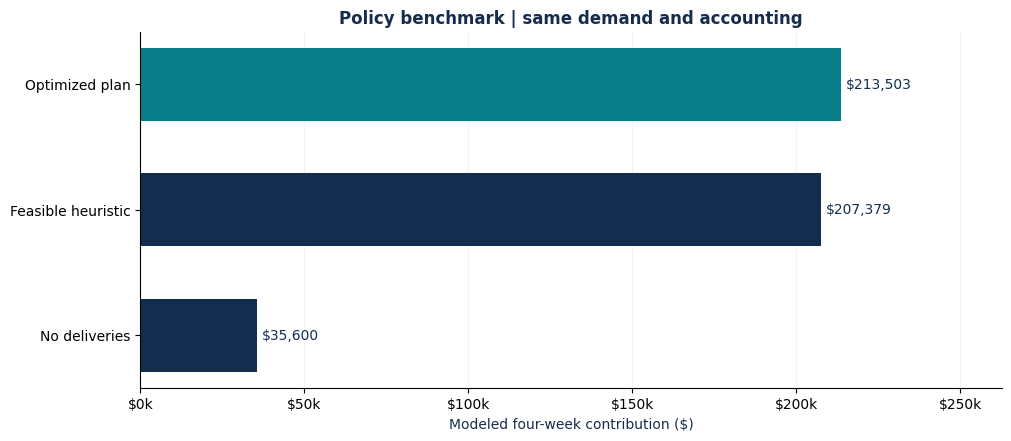

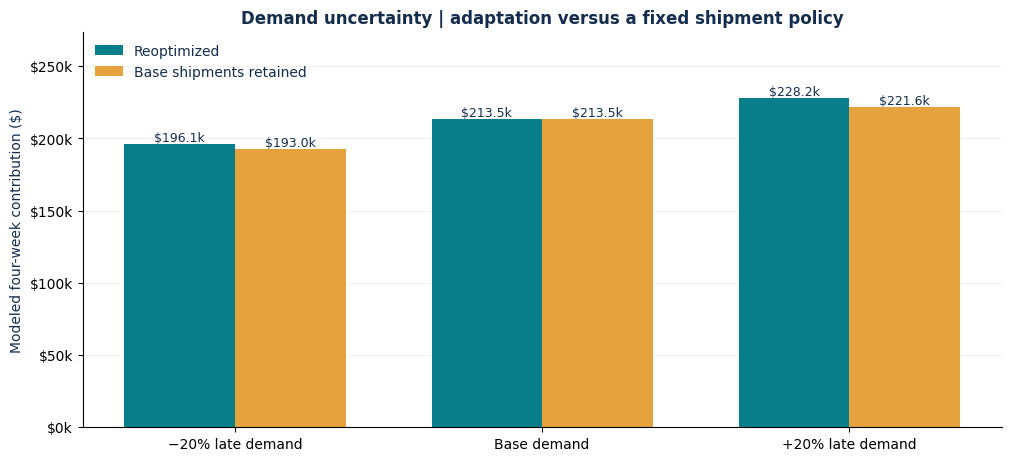

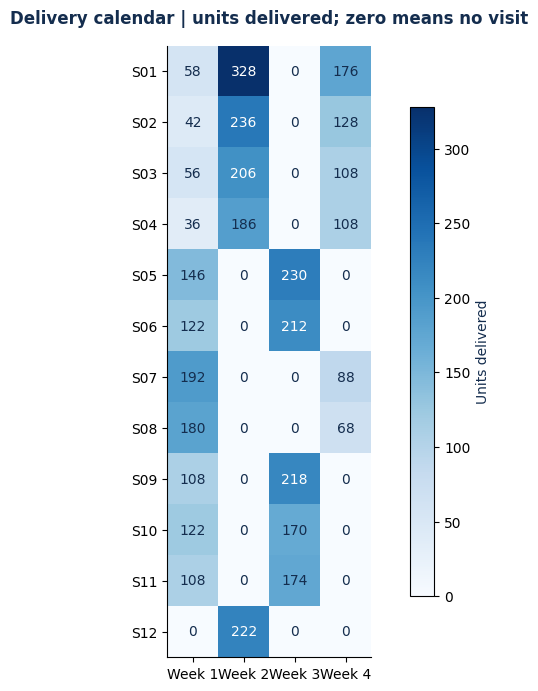

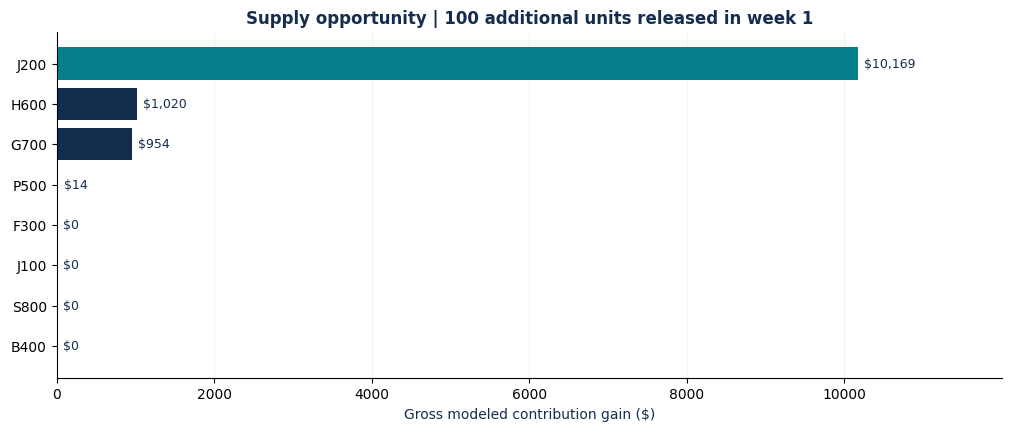

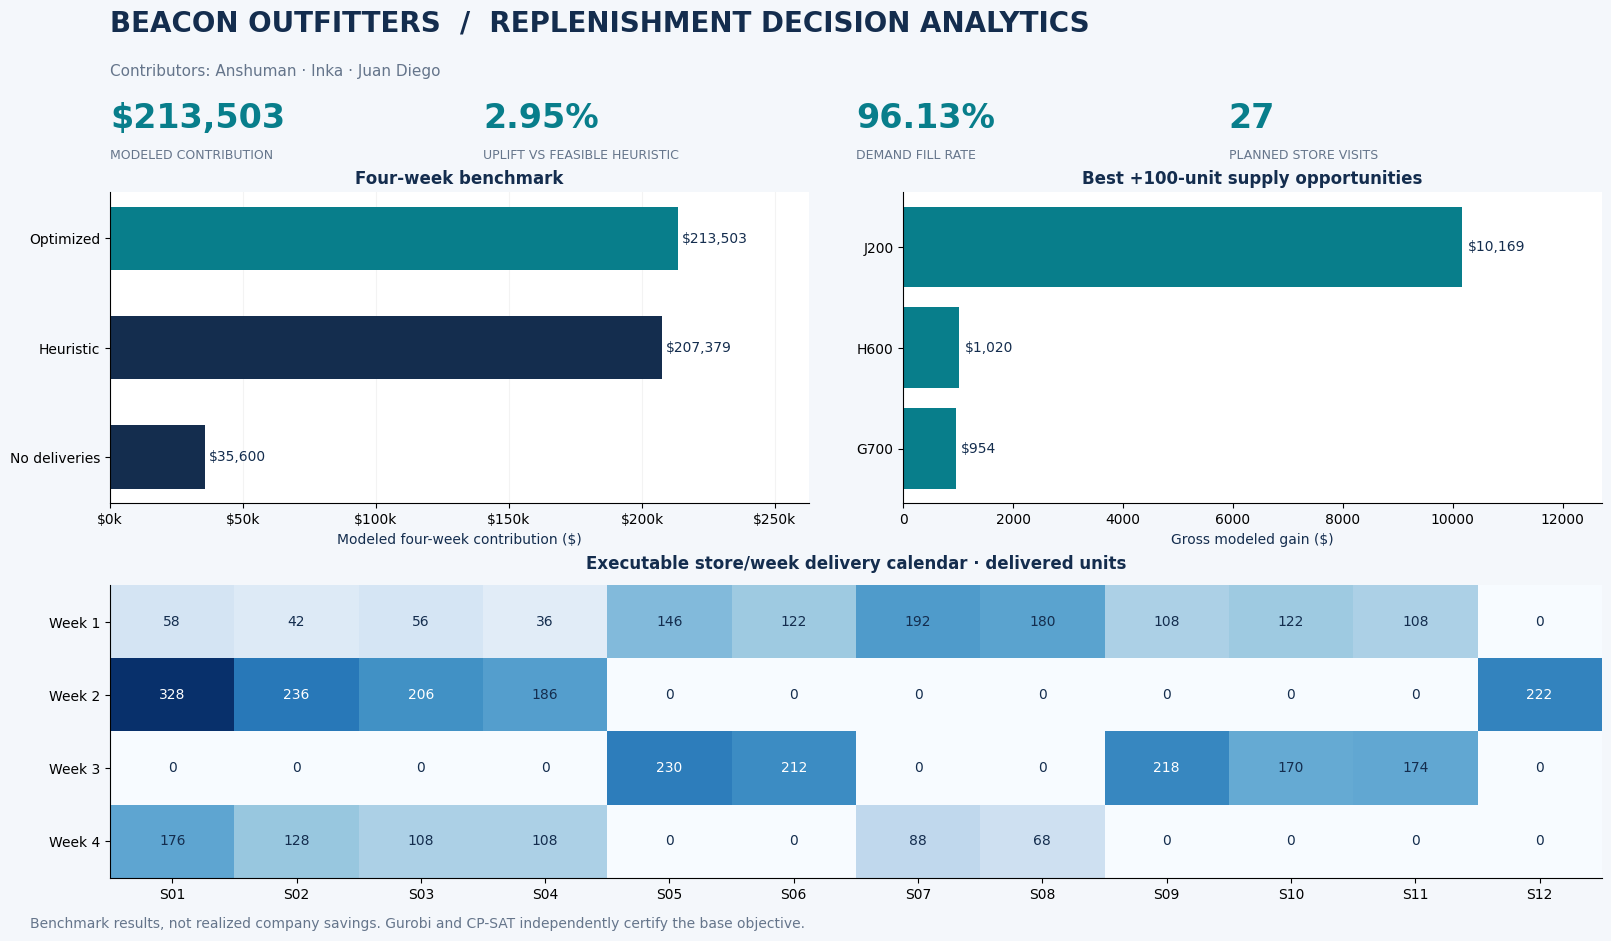

In [11]:
with pd.option_context('display.max_rows', 500):
    display(runs['base']['plan'].query('cases>0'))
    display(trucks)
display(pd.read_csv('beacon_results/tables/weekly_financials.csv'))
charts(summary, trucks, out='beacon_results/figures')

## 8. Baselines, bottlenecks and forecast sensitivity
Extra 100-unit opportunities arrive in week 1. Finite re-solves measure total profit gains, not LP shadow prices. Alternate-week deliveries are restricted to either odd or even weeks per store. Fixed-policy scenarios preserve original cases and visits while adjusting sales and inventory.

In [12]:
for filename in ['baseline_comparison','sku_bottleneck','sensitivity_results','dc_constraints','shortages','sku_summary','decision_changes','feasibility_checks']:
    print(filename); display(pd.read_csv('beacon_results/tables/'+filename+'.csv'))
print('Actual small/large store delivery economics:')
economics=trucks.groupby('store_id')[['units_shipped','delivery_cost','visit']].sum()
economics['cost_per_delivered_unit']=economics.delivery_cost/economics.units_shipped
display(economics.join(store_stats[['four_week_demand']]).sort_values('four_week_demand'))

baseline_comparison


,profit,sales_margin,holding_cost,delivery_cost,units_sold,units_lost,fill_rate,cases,units_shipped,visits,scenario,status,profit_difference_vs_base_no_delivery,profit_difference_vs_base_heuristic
0,213503.10,221013.0,1399.90,6110,4598.0,185.0,0.961321,512,4028,27,base,OPTIMAL,177903.35,6123.90
1,35599.75,35612.0,12.25,0,754.0,4029.0,0.157642,0,0,0,do_nothing,OPTIMAL,0.00,-171779.45
2,207379.20,219425.0,565.80,11480,4556.0,227.0,0.952540,513,4034,48,naive,OPTIMAL,171779.45,0.00


sku_bottleneck


,sku,release_week,extra_units,profit,profit_gain,status,base_status
0,J200,1,100,223672.300000,10169.200000,OPTIMAL,OPTIMAL
1,H600,1,100,214522.900000,1019.800000,OPTIMAL,OPTIMAL
2,G700,1,100,214457.000000,953.900000,OPTIMAL,OPTIMAL
3,P500,1,100,213516.700000,13.600000,OPTIMAL,OPTIMAL
4,F300,1,100,213503.100004,0.000004,OPTIMAL,OPTIMAL
5,J100,1,100,213503.100000,0.000000,OPTIMAL,OPTIMAL
6,B400,1,100,213503.100000,0.000000,OPTIMAL,OPTIMAL
7,S800,1,100,213503.100000,0.000000,OPTIMAL,OPTIMAL


sensitivity_results


,profit,sales_margin,holding_cost,delivery_cost,units_sold,units_lost,fill_rate,cases,units_shipped,visits,scenario,status,profit_difference_vs_base_no_delivery,profit_difference_vs_base_heuristic
0,213503.10,221013.0,1399.90,6110,4598.0,185.0,0.961321,512,4028,27,base,OPTIMAL,177903.35,6123.90
1,210379.10,217375.0,1255.90,5740,4513.0,270.0,0.943550,503,3960,24,alternate_week,OPTIMAL,174779.35,2999.90
2,196074.61,203895.8,1411.19,6410,4214.6,34.8,0.991811,477,3778,28,lower,OPTIMAL,160474.86,-11304.59
3,192979.83,200809.4,1719.57,6110,4158.6,90.8,0.978632,512,4028,27,lower_fixed,OPTIMAL,157380.08,-14399.37
4,228223.15,235658.6,1465.45,5970,4871.0,445.6,0.916187,550,4300,27,higher,OPTIMAL,192623.40,20843.95
5,221594.99,228928.0,1223.01,6110,4749.6,567.0,0.893353,512,4028,27,higher_fixed,OPTIMAL,185995.24,14215.79


... (8 outputs left out)

feasibility_checks


,family,violation,passed,scenario
0,binary_visit,0.0,True,base
1,case_units,0.0,True,base
2,cumulative_dc,0.0,True,base
3,demand,0.0,True,base
4,finite,0.0,True,base
...,...,...,...,...
199,objective,0.0,True,extra_S800
200,shelf,0.0,True,extra_S800
201,truck,0.0,True,extra_S800
202,whole_cases,0.0,True,extra_S800


Actual small/large store delivery economics:


,units_shipped,delivery_cost,visit,cost_per_delivered_unit,four_week_demand
store_id,,,,,
S08,248,760,2,3.064516,294
S12,222,300,1,1.351351,307
S10,292,400,2,1.369863,325
S11,282,480,2,1.702128,331
S07,280,520,2,1.857143,341
S04,330,360,3,1.090909,373
S06,334,640,2,1.916168,381
S09,326,520,2,1.595092,392
S05,376,480,2,1.276596,430


## 9. Executive decision and consistency checks
The memo and briefing are generated from this same pipeline. Expected figures below are regression checks for the preserved source data; feasible time-limited solutions are never presented as proven optima.

In [13]:
s=summary.set_index('scenario')
best=pd.read_csv('beacon_results/tables/sku_bottleneck.csv').iloc[0]
if s.loc['base','status']=='OPTIMAL':
    assert abs(s.loc['base','profit']-213503.10)<0.011
assert pd.read_csv('beacon_results/tables/feasibility_checks.csv').passed.all()
assert abs(pd.read_csv('beacon_results/tables/weekly_financials.csv').profit.sum()-s.loc['base','profit'])<0.011
display(Markdown(f"""**Base plan:** ${s.loc['base','profit']:,.2f} contribution profit,
{s.loc['base','visits']:.0f} visits, {s.loc['base','cases']:.0f} cases.
Profit uplift: ${s.loc['base','profit']-s.loc['do_nothing','profit']:,.2f} versus no deliveries;
${s.loc['base','profit']-s.loc['naive','profit']:,.2f} versus the feasible heuristic.
Best 100-unit opportunity: **{best.sku}**, ${best.profit_gain:,.2f} gross gain.
Alternate-week restriction costs ${s.loc['base','profit']-s.loc['alternate_week','profit']:,.2f}.
Lower/higher forecast reoptimization: ${s.loc['lower','profit']:,.2f} / ${s.loc['higher','profit']:,.2f}.
Keeping the base shipments instead: ${s.loc['lower_fixed','profit']:,.2f} / ${s.loc['higher_fixed','profit']:,.2f}.
Use the truck calendar and case-level table above; refresh the plan when forecasts change.
**Review:** validate operational assumptions and the shipment calendar before adopting the policy.
"""))


**Base plan:** $213,503.10 contribution profit,
27 visits, 512 cases.
Profit uplift: $177,903.35 versus no deliveries;
$6,123.90 versus the feasible heuristic.
Best 100-unit opportunity: **J200**, $10,169.20 gross gain.
Alternate-week restriction costs $3,124.00.
Lower/higher forecast reoptimization: $196,074.61 / $228,223.15.
Keeping the base shipments instead: $192,979.83 / $221,594.99.
Use the truck calendar and case-level table above; refresh the plan when forecasts change.
**Review:** validate operational assumptions and the shipment calendar before adopting the policy.


## 10. Reproducibility, source credit and AI assistance

Original benchmark data and modeling reference: Hasan Arslan's
[public repository](https://github.com/harslan/isom-839).
The original five CSVs remain unchanged; source attribution and file hashes are
recorded in `docs/data_provenance.md`.

ChatGPT assisted debugging and technical explanations. OpenAI Codex assisted
implementation, testing, documentation and artifact generation. Contributors
remain responsible for reviewing the model and interpretation.

The run writes data/model hashes, solver versions, bounds, gaps and independent
checks. Local fresh-kernel execution is tested separately from hosted Google
Colab execution; no hosted execution claim is made without a hosted run.
